# Identify current sheet crossings and plot the magnetometer data with the JEDI data for these intervals.

In [51]:
import os
import re
import glob
import numpy as np
import datetime as dt
import matplotlib.pyplot as plt

from matplotlib.ticker import AutoMinorLocator

from JunoPy.index import IndexFile
from JunoPy.mag import MagData
from JunoPy.jedi import JediData
from JunoPy.library import find_ticks_between

In [52]:
# Fetch JEDI index file. (need for downloading)
jediindex = IndexFile(dataset='jedi')

##  Plotting function defined for mag and jedi. 

In [53]:
def plot_data(magdata, jedidata, start, end, outfolder=None, savefilename=None):
    """Plot data between start and end."""
    
    # Slice the data.
    try:
        magdata.df = magdata.df.loc[start:end]
        for jdata in jedidata:
            jdata.df = jdata.df.loc[start:end]
    except:
        pass
    
    
    # Find the ticks.
    timearray, tickstring = find_ticks_between(start, end)
    
    # Create the figure.
    fig, axs = plt.subplots(4 + len(jedidata), 1, 
                            gridspec_kw={'hspace': 0, 'right':0.9, 'top':0.9}, 
                            figsize=(9, 11), 
                            dpi=300)
    
    axs[:4] = magdata.plot(vars=['Br', 'Btheta', 'Bphi', 'Bmag'], axs=axs[:4])
    
    for i, jdata in enumerate(jedidata):
        if 'LO' in jdata.filename:
            axs[4 + i] = jdata.plot_low_res_line_plots(
                axs[4 + i], iTele=0)
        else:
            axs[4 + i] = jdata.plot_flux_spectra(
                axs[4 + i], iTele=0)
        
        axs[4 + i].set_ylabel('JEDI e$^{-}$ Flux\n' + 'Sensor - ' + 
                              os.path.split(jdata.filename)[-1][4:7])
    
    for a in axs:
        # a.set_xlim([timearray[0], timearray[-1]])
        a.set_xticks(timearray)
        a.set_xticklabels(tickstring)
        a.label_outer()
#         a.axvline(dt.datetime.strptime('2018-085T15:53:45', '%Y-%jT%H:%M:%S'), color='red', lw=0.5)
#         a.axvline(dt.datetime.strptime('2018-085T15:54:15', '%Y-%jT%H:%M:%S'), color='red', lw=0.5)
        
#     for a in axs[:4]:
#         a.axvspan(start + dt.timedelta(minutes=5), 
#                   end - dt.timedelta(minutes=5), alpha=0.2, color=[0.2, 0.2, 0.2])
            
    a.tick_params(axis='x', width=2, rotation=0)
    a.xaxis.label.set_visible(False)
    
    plt.suptitle(dt.datetime.strftime(start, '%Y-%m-%d') + \
                 ', DOY={:s}'.format(dt.datetime.strftime(start, '%j')), y=0.92)
    
    if outfolder:
        fig.savefig(outfolder + dt.datetime.strftime(start, '%Y-%jT%H:%M') + '.png')
        plt.close(fig)
    
    
    if savefilename:
        fig.savefig(savefilename)
        plt.close(fig)
    # fig.savefig('out_flapping/' + dt.datetime.strftime(start, '%Y-%jT%H:%M') + '.png')
    
    # plt.close(fig)

## Plot individual files but don't save them. (for exploration only)

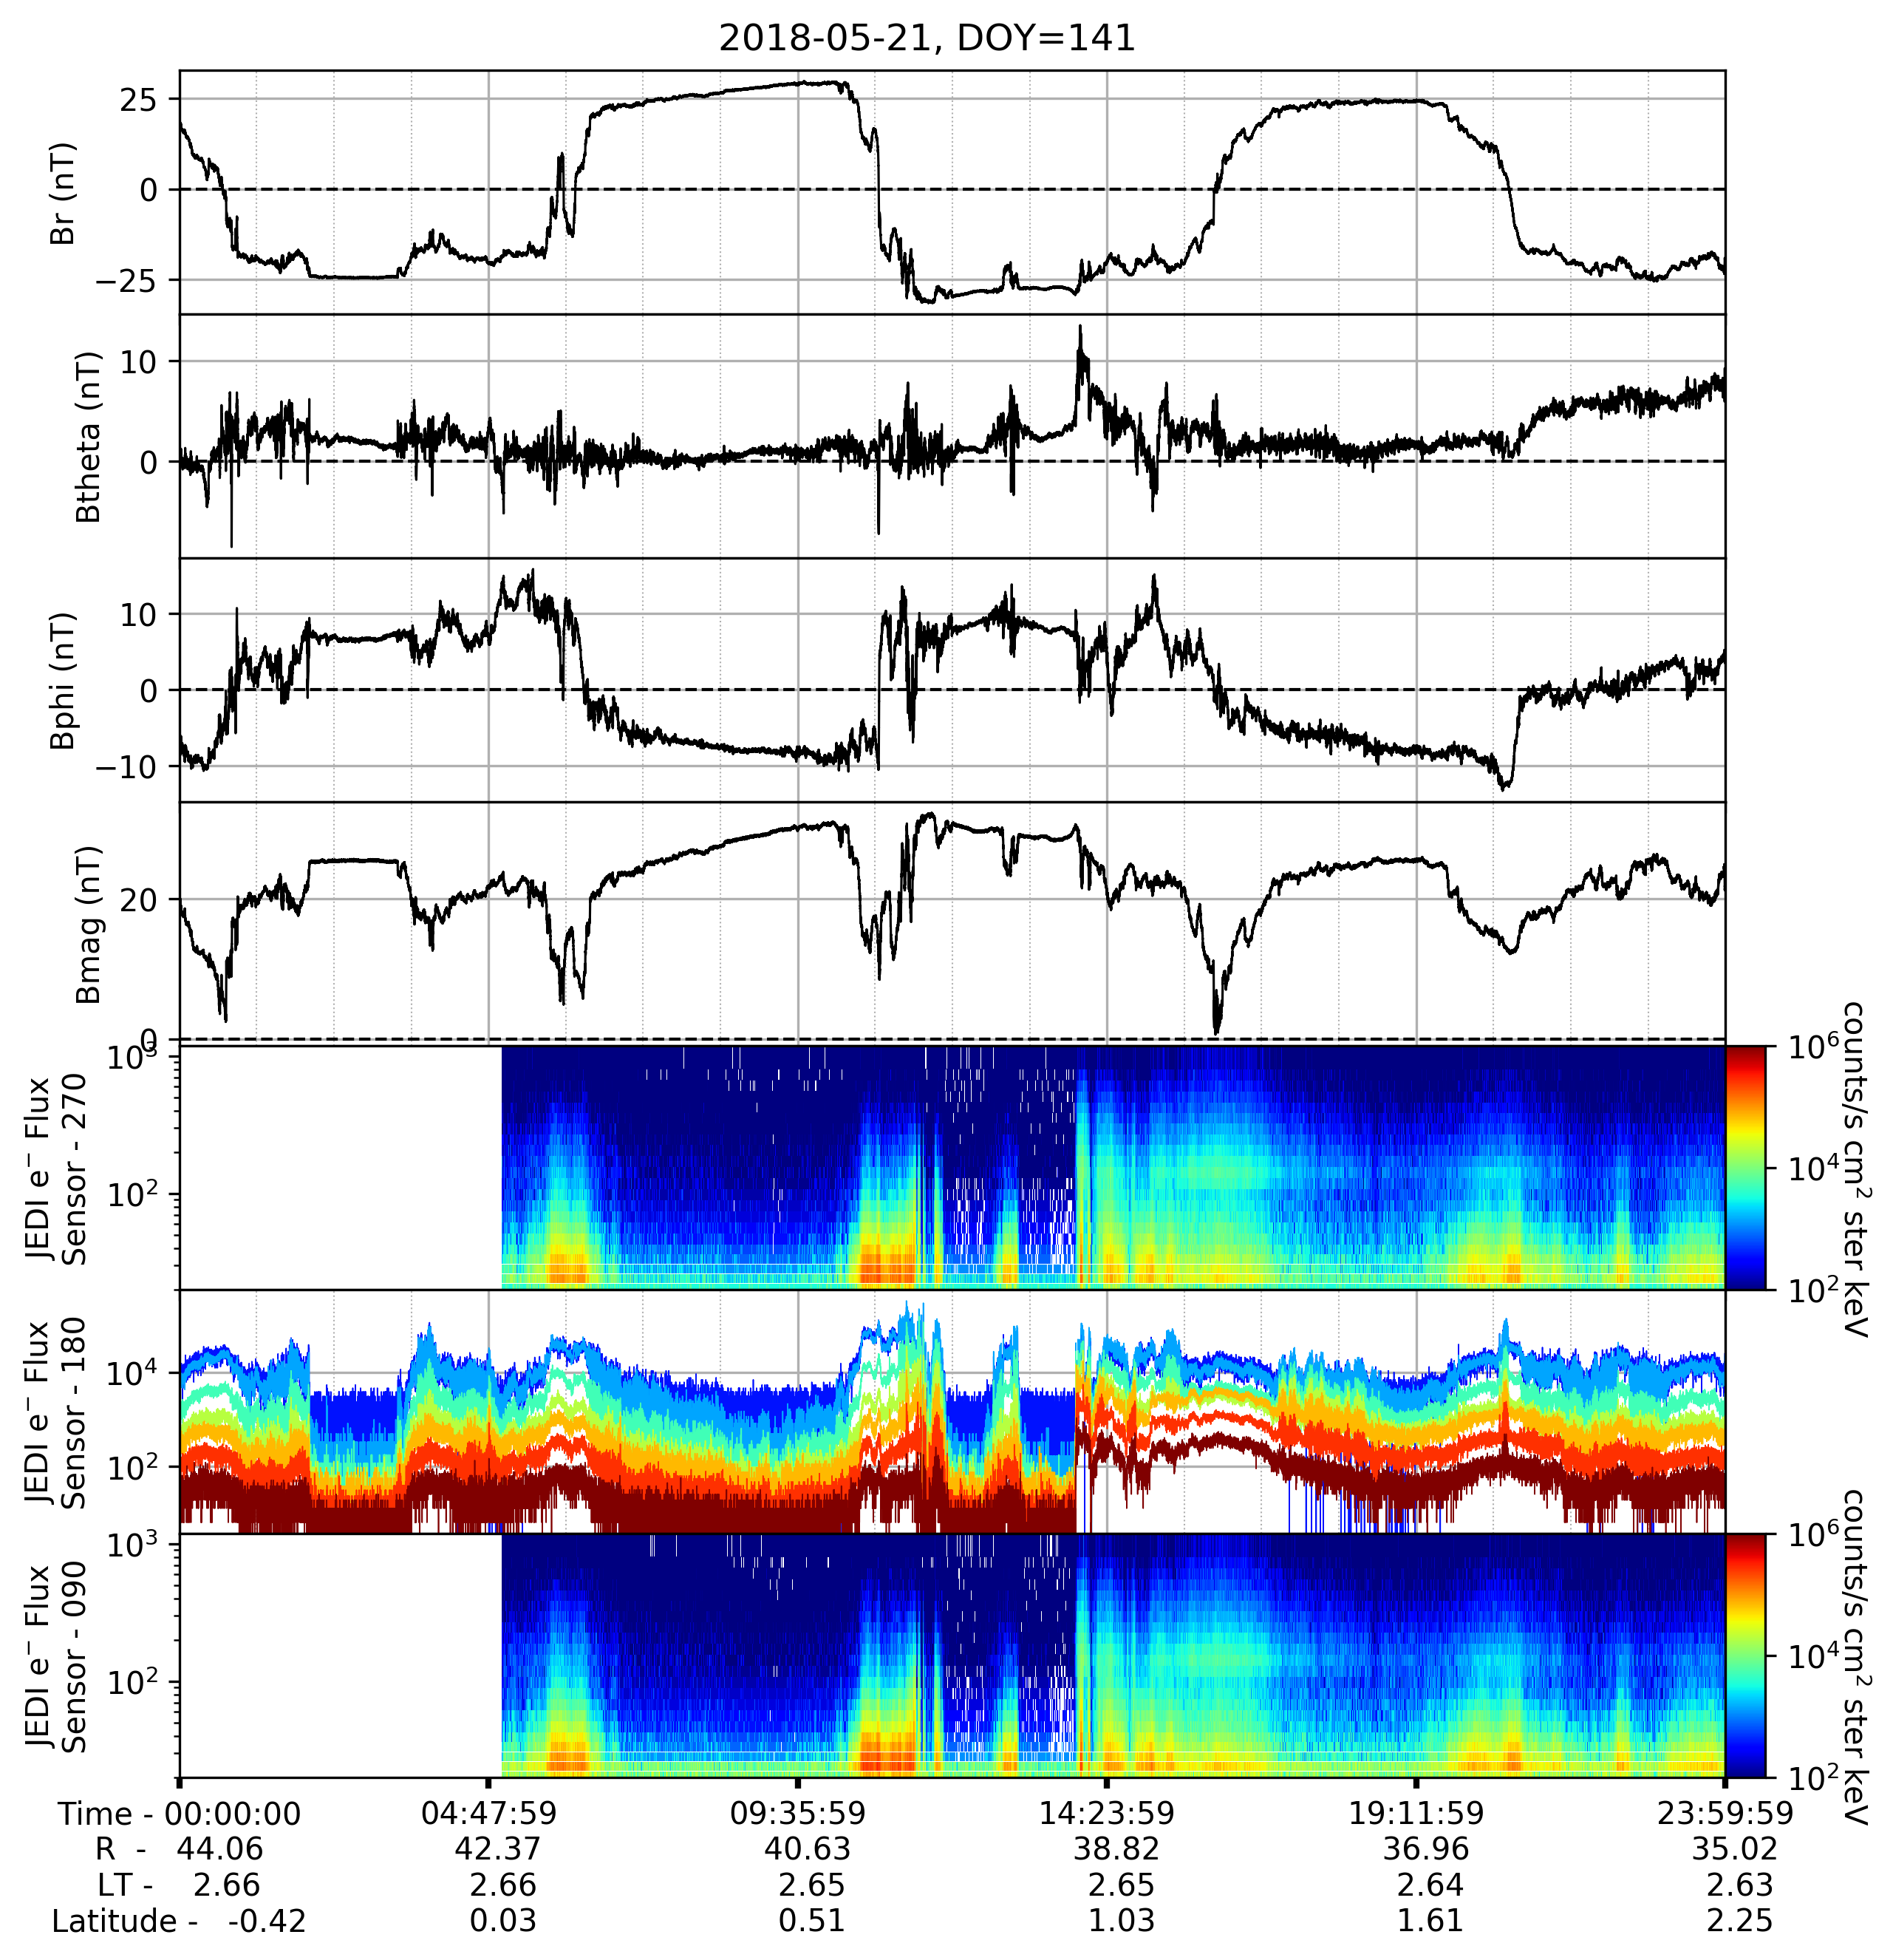

In [55]:
start = dt.datetime.strptime('2018-141T00:00:00', '%Y-%jT%H:%M:%S')
end   = dt.datetime.strptime('2018-141T23:59:59', '%Y-%jT%H:%M:%S')
    
magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
magdata = MagData(filename=magfile)
        
jedifiles = glob.glob('data/jedi/*_{:s}_*.TAB'.format(start.strftime('%Y%j')))
if not jedifiles:
    jediindex.get_files_between_dates(
        start, end, DoDownload=True, sid='ERSESP')
    jedifiles = glob.glob('data/jedi/*_{:s}_*.TAB'.format(start.strftime('%Y%j')))
    
jedidata = []
for jedifile in jedifiles:
    jedidata.append(JediData(filename=jedifile))
    
plot_data(magdata, jedidata, start, end)

In [ ]:
plot_data(magdata, jedidata, start, end, 
          savefilename='out_interesting/{:s}-mag-jedi.png'.format(
              dt.datetime.strftime(start, '%Y-%j')))

## Identify flapping intervals. 


In [ ]:
currentsheet_intervals = [
    '2019-147T17:30:00 2019-147T20:30:00 no',
    
]

In [ ]:
def save_dates_csv(dates):
    """Save the list of epochs in a csv file with columns - start, end, duration"""
    with open('flapping_intervals.csv', 'w') as f:
        f.write('Start,End,IsFlapping')
        for date in dates:
            f.write(','.join(date.split()[:2]))
            start = dt.datetime.strptime(date.split()[0], '%Y-%jT%H:%M:%S')
            end = dt.datetime.strptime(date.split()[1], '%Y-%jT%H:%M:%S')
            if 'yes' in date.split()[2]:
                f.write(',yes\n')
            else:
                f.write(',no\n')

## Plot and save the data for specified intervals.

In [ ]:
for date in currentsheet_intervals:
    
    start = dt.datetime.strptime(date.split()[0], '%Y-%jT%H:%M:%S')
    end = dt.datetime.strptime(date.split()[1], '%Y-%jT%H:%M:%S')
    
    magfile = glob.glob('data/mag/*{:s}ss*.hdf5'.format(start.strftime('%Y%j')))[0]
    magdata = MagData(filename=magfile)
        
    jedifiles = glob.glob('data/jedi/*_{:s}_*.TAB'.format(start.strftime('%Y%j')))
    if not jedifiles:
        jediindex.get_files_between_dates(
            start, end, DoDownload=True, sid='ERSESP')
        jedifiles = glob.glob('data/jedi/*_{:s}_*.TAB'.format(start.strftime('%Y%j')))
    
    jedidata = []
    for jedifile in jedifiles:
        jedidata.append(JediData(filename=jedifile))
    
    plot_data(magdata, jedidata, start, end, outfolder='out_flapping/')